# Joins and Set Operations

Normalised data is spread over many tables (Lesson 02). **Joins** combine rows from several tables by matching keys. **Set operations** combine the results of several queries.

**After this lesson you can:**

1. Use `INNER`, `LEFT`, `RIGHT`, `FULL OUTER`, `CROSS` and self joins.
2. Find rows without a match (anti-join).
3. Detect the "fan-out" problem that inflates sums.
4. Use `UNION`, `UNION ALL`, `INTERSECT` and `EXCEPT`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

## 1. Join Types

| Join | Returns |
| :--- | :--- |
| `INNER JOIN` | only rows with a match in both tables |
| `LEFT JOIN` | all rows of the left table; NULLs where the right side has no match |
| `RIGHT JOIN` | all rows of the right table |
| `FULL OUTER JOIN` | all rows of both tables |
| `CROSS JOIN` | every combination (rows × rows) |

The experiment counts the rows that each join type returns for **artists** and **albums**. Some artists in Chinook have no album.

In [2]:
counts = {}
for join in ["INNER JOIN", "LEFT JOIN", "RIGHT JOIN", "FULL OUTER JOIN"]:
    counts[join] = q(f"SELECT count(*) AS n FROM artist ar {join} album al ON al.artist_id = ar.artist_id")["n"][0]
counts["CROSS JOIN"] = q("SELECT count(*) AS n FROM artist CROSS JOIN album")["n"][0]
base = q("SELECT (SELECT count(*) FROM artist) AS artists, (SELECT count(*) FROM album) AS albums")
print(base.to_string(index=False))
pd.Series(counts, name="rows")

 artists  albums
     275     347


INNER JOIN           347
LEFT JOIN            418
RIGHT JOIN           347
FULL OUTER JOIN      418
CROSS JOIN         95425
Name: rows, dtype: int64

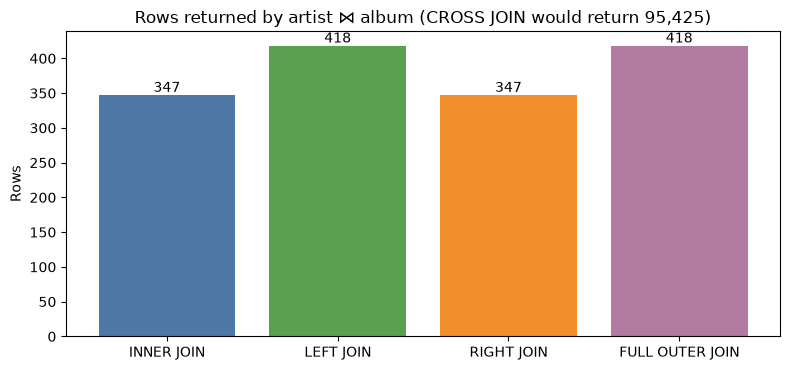

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
names = [k for k in counts if k != "CROSS JOIN"]
ax.bar(names, [counts[k] for k in names], color=["#4E79A7", "#59A14F", "#F28E2B", "#B07AA1"])
for i, k in enumerate(names):
    ax.text(i, counts[k], f"{counts[k]}", ha="center", va="bottom")
ax.set(title=f"Rows returned by artist ⋈ album (CROSS JOIN would return {counts['CROSS JOIN']:,})", ylabel="Rows")
plt.tight_layout()
plt.show()

`LEFT JOIN` returns more rows than `INNER JOIN`: the extra rows are the artists without albums, with NULL in the album columns. `RIGHT JOIN` equals `INNER JOIN` here, because every album has an artist (a foreign key guarantees it).

## 2. Anti-Join: Rows Without a Match

"Which artists have no albums?" Two common forms:

- `LEFT JOIN ... WHERE right.key IS NULL`
- `WHERE NOT EXISTS (subquery)`

In [4]:
no_album = q("""
SELECT ar.name FROM artist ar
LEFT JOIN album al ON al.artist_id = ar.artist_id
WHERE al.album_id IS NULL
ORDER BY ar.name
""")
never_sold = q("""
SELECT count(*) AS tracks_never_sold FROM track t
WHERE NOT EXISTS (SELECT 1 FROM invoice_line il WHERE il.track_id = t.track_id)
""")
print(f"{len(no_album)} artists without albums, e.g. {', '.join(no_album['name'].head(3))}")
never_sold

71 artists without albums, e.g. Academy of St. Martin in the Fields, Sir Neville Marriner & William Bennett, A Cor Do Som, Aerosmith & Sierra Leone's Refugee Allstars


,tracks_never_sold
0,1519


## 3. Self Join: the Management Hierarchy

A table can join to itself with two aliases. `employee.reports_to` points to another employee.

In [5]:
q("""
SELECT e.first_name || ' ' || e.last_name AS employee, e.title,
       coalesce(m.first_name || ' ' || m.last_name, '(top)') AS manager,
       (SELECT count(*) FROM customer c WHERE c.support_rep_id = e.employee_id) AS customers_supported
FROM employee e
LEFT JOIN employee m ON m.employee_id = e.reports_to
ORDER BY e.employee_id
""")

,employee,title,manager,customers_supported
0,Andrew Adams,General Manager,(top),0
1,Nancy Edwards,Sales Manager,Andrew Adams,0
2,Jane Peacock,Sales Support Agent,Nancy Edwards,21
3,Margaret Park,Sales Support Agent,Nancy Edwards,20
4,Steve Johnson,Sales Support Agent,Nancy Edwards,18
5,Michael Mitchell,IT Manager,Andrew Adams,0
6,Robert King,IT Staff,Michael Mitchell,0
7,Laura Callahan,IT Staff,Michael Mitchell,0


## 4. The Fan-Out Trap

Joining a "one" table to a "many" table repeats the "one" side for every match. If you then `SUM` a column from the "one" side, you count it several times. The example computes revenue per country in a correct and an incorrect way.

In [6]:
correct = q("SELECT sum(total) AS revenue FROM invoice")["revenue"][0]
wrong = q("""SELECT sum(i.total) AS revenue FROM invoice i
             JOIN invoice_line il ON il.invoice_id = i.invoice_id""")["revenue"][0]
from_lines = q("SELECT sum(unit_price * quantity) AS revenue FROM invoice_line")["revenue"][0]
print(f"sum of invoice totals               : {correct:10,.2f}")
print(f"same sum after joining invoice lines : {wrong:10,.2f}  <- inflated {wrong / correct:.1f}x")
print(f"sum computed at the line level        : {from_lines:10,.2f}")

sum of invoice totals               :   2,328.60
same sum after joining invoice lines :  20,848.62  <- inflated 9.0x
sum computed at the line level        :   2,328.60


Every invoice total was repeated once per invoice line. Rule: aggregate at the **grain** of the column you sum (the invoice level for `invoice.total`, the line level for `unit_price * quantity`), or aggregate before you join.

## 5. Set Operations

| Operation | Result | Duplicates |
| :--- | :--- | :--- |
| `UNION` | rows in either query | removed |
| `UNION ALL` | rows in either query | kept (faster) |
| `INTERSECT` | rows in both queries | removed |
| `EXCEPT` | rows in the first query but not the second | removed |

Both queries must return the same number of columns with compatible types.

In [7]:
sets = q("""
SELECT 'customers'           AS what, count(*) FROM (SELECT DISTINCT country FROM customer) a
UNION ALL
SELECT 'employees',              count(*) FROM (SELECT DISTINCT country FROM employee) b
UNION ALL
SELECT 'in both (INTERSECT)',    count(*) FROM (SELECT country FROM customer INTERSECT SELECT country FROM employee) c
UNION ALL
SELECT 'customers only (EXCEPT)', count(*) FROM (SELECT country FROM customer EXCEPT SELECT country FROM employee) d
UNION ALL
SELECT 'either (UNION)',         count(*) FROM (SELECT country FROM customer UNION SELECT country FROM employee) e
""")
sets.columns = ["countries", "count"]
sets

,countries,count
0,customers,24
1,employees,1
2,in both (INTERSECT),1
3,customers only (EXCEPT),23
4,either (UNION),24


*Insight: Before every join, ask two questions: "what is one row of each table?" and "which rows do I want when there is no match?". The first prevents fan-out errors in sums; the second decides between `INNER` and `LEFT` joins.*

## Real-World Use Case or Analogy

Joins are like **matching guest lists**. An inner join is the list of people who were invited *and* came. A left join is the full invitation list with a "came: yes/no" column. An anti-join is the list of people who were invited but did not come — often the most interesting list (customers who never bought again, tracks that never sold).

Almost every analytical query joins facts (orders, clicks, payments) to dimensions (customers, products, dates). The fan-out trap is one of the most common causes of wrong numbers in dashboards.